In [1]:

import pandas as pd
import numpy as np

# Upload your existing Olist closed deals CSV
from google.colab import files
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Saving olist_closed_deals_dataset.csv to olist_closed_deals_dataset.csv
Dataset loaded successfully!
Shape: (842, 14)

Column names:
['mql_id', 'seller_id', 'sdr_id', 'sr_id', 'won_date', 'business_segment', 'lead_type', 'lead_behaviour_profile', 'has_company', 'has_gtin', 'average_stock', 'business_type', 'declared_product_catalog_size', 'declared_monthly_revenue']

First 5 rows:


,mql_id,seller_id,sdr_id,sr_id,won_date,business_segment,lead_type,lead_behaviour_profile,has_company,has_gtin,average_stock,business_type,declared_product_catalog_size,declared_monthly_revenue
0,5420aad7fec3549a85876ba1c529bd84,2c43fb513632d29b3b58df74816f1b06,a8387c01a09e99ce014107505b92388c,4ef15afb4b2723d8f3d81e51ec7afefe,2018-02-26 19:58:54,pet,online_medium,cat,NaN,NaN,NaN,reseller,NaN,0.0
1,a555fb36b9368110ede0f043dfc3b9a0,bbb7d7893a450660432ea6652310ebb7,09285259593c61296eef10c734121d5b,d3d1e91a157ea7f90548eef82f1955e3,2018-05-08 20:17:59,car_accessories,industry,eagle,NaN,NaN,NaN,reseller,NaN,0.0
2,327174d3648a2d047e8940d7d15204ca,612170e34b97004b3ba37eae81836b4c,b90f87164b5f8c2cfa5c8572834dbe3f,6565aa9ce3178a5caf6171827af3a9ba,2018-06-05 17:27:23,home_appliances,online_big,cat,NaN,NaN,NaN,reseller,NaN,0.0
3,f5fee8f7da74f4887f5bcae2bafb6dd6,21e1781e36faf92725dde4730a88ca0f,56bf83c4bb35763a51c2baab501b4c67,d3d1e91a157ea7f90548eef82f1955e3,2018-01-17 13:51:03,food_drink,online_small,NaN,NaN,NaN,NaN,reseller,NaN,0.0
4,ffe640179b554e295c167a2f6be528e0,ed8cb7b190ceb6067227478e48cf8dde,4b339f9567d060bcea4f5136b9f5949e,d3d1e91a157ea7f90548eef82f1955e3,2018-07-03 20:17:45,home_appliances,industry,wolf,NaN,NaN,NaN,manufacturer,NaN,0.0


In [2]:

# STEP 2: Data Quality Assessment

print("DATASET SHAPE:", df.shape)

print("\n1. COLUMN DATA TYPES")
display(df.dtypes.astype(str).rename("Data Type").to_frame())

print("\n2. MISSING VALUES")
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})
display(missing.sort_values("Missing Percentage", ascending=False))

print("\n3. DUPLICATE CHECK")
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate lead IDs:", df["mql_id"].duplicated().sum())

print("\n4. CONVERSION DATE CHECK")
print("Missing won_date:", df["won_date"].isnull().sum())


DATASET SHAPE: (842, 14)

1. COLUMN DATA TYPES


,Data Type
mql_id,object
seller_id,object
sdr_id,object
sr_id,object
won_date,object
business_segment,object
lead_type,object
lead_behaviour_profile,object
has_company,object
has_gtin,object



2. MISSING VALUES


,Missing Count,Missing Percentage
has_company,779,92.52
has_gtin,778,92.40
average_stock,776,92.16
declared_product_catalog_size,773,91.81
lead_behaviour_profile,177,21.02
business_type,10,1.19
lead_type,6,0.71
business_segment,1,0.12
won_date,0,0.00
seller_id,0,0.00



3. DUPLICATE CHECK
Duplicate rows: 0
Duplicate lead IDs: 0

4. CONVERSION DATE CHECK
Missing won_date: 0


In [3]:

# STEP 3: Clean and prepare the dataset

df_clean = df.copy()

# Convert the conversion date to datetime
df_clean["won_date"] = pd.to_datetime(
    df_clean["won_date"], errors="coerce"
)

# Standardize text columns and mark missing categorical values
categorical_cols = [
    "business_segment",
    "lead_type",
    "lead_behaviour_profile",
    "business_type",
    "has_company",
    "has_gtin",
    "average_stock"
]

for col in categorical_cols:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
        .fillna("Unknown")
    )

# Keep the original numeric values and their missing values.
# Do not invent values for highly incomplete numeric columns.

print("CLEANING COMPLETE")
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Duplicate rows:", df_clean.duplicated().sum())
print("Missing conversion dates:", df_clean["won_date"].isna().sum())

print("\nRemaining missing values:")
display(
    df_clean.isna().sum()
    .to_frame("Missing Count")
    .query("`Missing Count` > 0")
)

display(df_clean.head())


CLEANING COMPLETE
Original rows: 842
Cleaned rows: 842
Duplicate rows: 0
Missing conversion dates: 0

Remaining missing values:


,Missing Count
declared_product_catalog_size,773


,mql_id,seller_id,sdr_id,sr_id,won_date,business_segment,lead_type,lead_behaviour_profile,has_company,has_gtin,average_stock,business_type,declared_product_catalog_size,declared_monthly_revenue
0,5420aad7fec3549a85876ba1c529bd84,2c43fb513632d29b3b58df74816f1b06,a8387c01a09e99ce014107505b92388c,4ef15afb4b2723d8f3d81e51ec7afefe,2018-02-26 19:58:54,pet,online_medium,cat,Unknown,Unknown,Unknown,reseller,NaN,0.0
1,a555fb36b9368110ede0f043dfc3b9a0,bbb7d7893a450660432ea6652310ebb7,09285259593c61296eef10c734121d5b,d3d1e91a157ea7f90548eef82f1955e3,2018-05-08 20:17:59,car_accessories,industry,eagle,Unknown,Unknown,Unknown,reseller,NaN,0.0
2,327174d3648a2d047e8940d7d15204ca,612170e34b97004b3ba37eae81836b4c,b90f87164b5f8c2cfa5c8572834dbe3f,6565aa9ce3178a5caf6171827af3a9ba,2018-06-05 17:27:23,home_appliances,online_big,cat,Unknown,Unknown,Unknown,reseller,NaN,0.0
3,f5fee8f7da74f4887f5bcae2bafb6dd6,21e1781e36faf92725dde4730a88ca0f,56bf83c4bb35763a51c2baab501b4c67,d3d1e91a157ea7f90548eef82f1955e3,2018-01-17 13:51:03,food_drink,online_small,Unknown,Unknown,Unknown,Unknown,reseller,NaN,0.0
4,ffe640179b554e295c167a2f6be528e0,ed8cb7b190ceb6067227478e48cf8dde,4b339f9567d060bcea4f5136b9f5949e,d3d1e91a157ea7f90548eef82f1955e3,2018-07-03 20:17:45,home_appliances,industry,wolf,Unknown,Unknown,Unknown,manufacturer,NaN,0.0


In [4]:

# STEP 4: Closed Deal Analysis by Business Segment

segment_analysis = (
    df_clean.groupby("business_segment", dropna=False)
    .agg(
        Closed_Deals=("mql_id", "nunique"),
        Sales_Representatives=("sr_id", "nunique"),
        Sales_Development_Reps=("sdr_id", "nunique")
    )
    .reset_index()
    .sort_values("Closed_Deals", ascending=False)
)

segment_analysis["Deal_Share_Percent"] = (
    segment_analysis["Closed_Deals"] / df_clean["mql_id"].nunique() * 100
).round(2)

print("CLOSED DEALS BY BUSINESS SEGMENT")
display(segment_analysis)

print("\nTOP 5 BUSINESS SEGMENTS")
display(segment_analysis.head(5))


CLOSED DEALS BY BUSINESS SEGMENT


,business_segment,Closed_Deals,Sales_Representatives,Sales_Development_Reps,Deal_Share_Percent
18,home_decor,105,17,21,12.47
16,health_beauty,93,17,17,11.05
7,car_accessories,77,17,18,9.14
20,household_utilities,71,17,16,8.43
9,construction_tools_house_garden,69,17,19,8.19
2,audio_video_electronics,64,17,17,7.60
8,computers,34,12,16,4.04
26,pet,30,12,12,3.56
12,food_supplement,28,13,14,3.33
11,food_drink,26,10,15,3.09



TOP 5 BUSINESS SEGMENTS


,business_segment,Closed_Deals,Sales_Representatives,Sales_Development_Reps,Deal_Share_Percent
18,home_decor,105,17,21,12.47
16,health_beauty,93,17,17,11.05
7,car_accessories,77,17,18,9.14
20,household_utilities,71,17,16,8.43
9,construction_tools_house_garden,69,17,19,8.19


In [6]:

# STEP 6: Sales Representative Performance

rep_analysis = (
    df_clean.groupby("sr_id")
    .agg(
        Closed_Deals=("mql_id", "nunique"),
        Business_Segments=("business_segment", "nunique")
    )
    .reset_index()
    .sort_values("Closed_Deals", ascending=False)
)

rep_analysis["Deal_Share_Percent"] = (
    rep_analysis["Closed_Deals"]
    / df_clean["mql_id"].nunique()
    * 100
).round(2)

print("TOP 10 SALES REPRESENTATIVES BY CLOSED DEALS")
display(rep_analysis.head(10))

print("\nTOTAL SALES REPRESENTATIVES:", rep_analysis["sr_id"].nunique())


TOP 10 SALES REPRESENTATIVES BY CLOSED DEALS


,sr_id,Closed_Deals,Business_Segments,Deal_Share_Percent
7,4ef15afb4b2723d8f3d81e51ec7afefe,133,27,15.80
19,d3d1e91a157ea7f90548eef82f1955e3,82,26,9.74
9,6565aa9ce3178a5caf6171827af3a9ba,74,23,8.79
11,85fc447d336637ba1df43e793199fbc8,64,22,7.60
5,495d4e95a8cf8bbf8b432b612a2aa328,63,20,7.48
3,2695de1affa7750089c0455f8ce27021,59,21,7.01
21,fbf4aef3f6915dc0c3c97d6812522f6a,59,18,7.01
20,de63de0d10a6012430098db33c679b0b,53,16,6.29
13,9ae085775a198122c5586fa830ff7f2b,51,17,6.06
18,c638112b43f1d1b86dcabb0da720c901,36,18,4.28



TOTAL SALES REPRESENTATIVES: 22


In [7]:
# STEP 7: Closed Deals by Lead Type

lead_type_analysis = (
    df_clean.groupby("lead_type")
    .agg(
        Closed_Deals=("mql_id", "nunique"),
        Sales_Representatives=("sr_id", "nunique")
    )
    .reset_index()
    .sort_values("Closed_Deals", ascending=False)
)

lead_type_analysis["Deal_Share_Percent"] = (
    lead_type_analysis["Closed_Deals"]
    / df_clean["mql_id"].nunique()
    * 100
).round(2)

print("CLOSED DEALS BY LEAD TYPE")
display(lead_type_analysis)

CLOSED DEALS BY LEAD TYPE


,lead_type,Closed_Deals,Sales_Representatives,Deal_Share_Percent
5,online_medium,332,21,39.43
4,online_big,126,18,14.96
1,industry,123,18,14.61
2,offline,104,17,12.35
6,online_small,77,17,9.14
3,online_beginner,57,15,6.77
7,online_top,14,9,1.66
0,Unknown,6,4,0.71
8,other,3,3,0.36


In [8]:
# STEP 8: Closed Deals by Business Type

business_type_analysis = (
    df_clean.groupby("business_type")
    .agg(
        Closed_Deals=("mql_id", "nunique"),
        Business_Segments=("business_segment", "nunique"),
        Sales_Representatives=("sr_id", "nunique")
    )
    .reset_index()
    .sort_values("Closed_Deals", ascending=False)
)

business_type_analysis["Deal_Share_Percent"] = (
    business_type_analysis["Closed_Deals"]
    / df_clean["mql_id"].nunique()
    * 100
).round(2)

print("CLOSED DEALS BY BUSINESS TYPE")
display(business_type_analysis)

CLOSED DEALS BY BUSINESS TYPE


,business_type,Closed_Deals,Business_Segments,Sales_Representatives,Deal_Share_Percent
3,reseller,587,32,21,69.71
1,manufacturer,242,25,19,28.74
0,Unknown,10,8,7,1.19
2,other,3,1,3,0.36


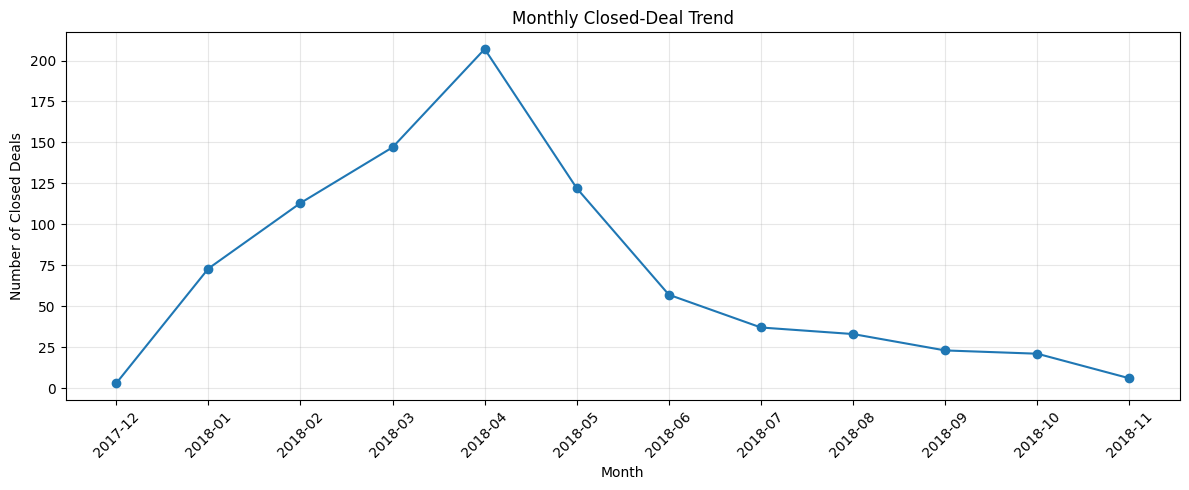

In [9]:
# STEP 9: Monthly Closed-Deal Trend

import matplotlib.pyplot as plt

monthly_chart = monthly_analysis.copy()

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_chart["won_month"],
    monthly_chart["Closed_Deals"],
    marker="o"
)

plt.title("Monthly Closed-Deal Trend")
plt.xlabel("Month")
plt.ylabel("Number of Closed Deals")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# STEP 10: Month-over-Month Change

monthly_change = monthly_analysis.copy()

monthly_change["Previous_Month_Deals"] = (
    monthly_change["Closed_Deals"].shift(1)
)

monthly_change["MoM_Change_Percent"] = (
    monthly_change["Closed_Deals"]
    .pct_change()
    .mul(100)
    .round(2)
)

print("MONTHLY CLOSED-DEAL PERFORMANCE")
display(monthly_change)

MONTHLY CLOSED-DEAL PERFORMANCE


,won_month,Closed_Deals,Previous_Month_Deals,MoM_Change_Percent
0,2017-12,3,NaN,NaN
1,2018-01,73,3.0,2333.33
2,2018-02,113,73.0,54.79
3,2018-03,147,113.0,30.09
4,2018-04,207,147.0,40.82
5,2018-05,122,207.0,-41.06
6,2018-06,57,122.0,-53.28
7,2018-07,37,57.0,-35.09
8,2018-08,33,37.0,-10.81
9,2018-09,23,33.0,-30.30


In [11]:
# STEP 11: Declared Monthly Revenue Analysis

revenue_summary = df_clean["declared_monthly_revenue"].describe()

print("DECLARED MONTHLY REVENUE SUMMARY")
display(revenue_summary.to_frame(name="Value"))

print("\nMISSING REVENUE VALUES:",
      df_clean["declared_monthly_revenue"].isna().sum())

print("\nTOP 10 DEALS BY DECLARED MONTHLY REVENUE")
display(
    df_clean[
        ["mql_id", "business_segment", "business_type",
         "declared_monthly_revenue"]
    ]
    .sort_values("declared_monthly_revenue", ascending=False)
    .head(10)
)

DECLARED MONTHLY REVENUE SUMMARY


,Value
count,8.420000e+02
mean,7.337768e+04
std,1.744799e+06
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
max,5.000000e+07



MISSING REVENUE VALUES: 0

TOP 10 DEALS BY DECLARED MONTHLY REVENUE


,mql_id,business_segment,business_type,declared_monthly_revenue
188,6a10f542e6f79265c34a405dbc928e37,construction_tools_house_garden,manufacturer,50000000.0
408,50523d9bd9d5d9a44bbc2f778954c5ae,phone_mobile,reseller,8000000.0
681,9dde4d7713ae64986ab6f5c9f9cf94d3,other,other,500000.0
589,30c1778642a506dbd803a0fa5ece533e,pet,reseller,300000.0
605,b39ac02ff5021fed10cb9988a23d5d02,home_decor,manufacturer,300000.0
813,3223fed48f30bbdc0f6040b466516bcb,construction_tools_house_garden,manufacturer,250000.0
392,010ed37e44e2fdc175b4c5c6c930805a,audio_video_electronics,reseller,250000.0
236,6d78dcbeb39103c047f486abd2519ee4,health_beauty,reseller,210000.0
838,8723201570415eb23b4f095d8c20a27c,construction_tools_house_garden,reseller,200000.0
59,a55b94066766f2d29fc22a3bb52d78f6,toys,reseller,180000.0


In [12]:
# STEP 12: Investigate Zero Revenue Values

zero_revenue = (
    df_clean["declared_monthly_revenue"] == 0
).sum()

positive_revenue = (
    df_clean["declared_monthly_revenue"] > 0
).sum()

negative_revenue = (
    df_clean["declared_monthly_revenue"] < 0
).sum()

total = len(df_clean)

revenue_quality = pd.DataFrame({
    "Category": [
        "Zero revenue",
        "Positive revenue",
        "Negative revenue"
    ],
    "Records": [
        zero_revenue,
        positive_revenue,
        negative_revenue
    ]
})

revenue_quality["Percentage"] = (
    revenue_quality["Records"] / total * 100
).round(2)

print("REVENUE VALUE DISTRIBUTION")
display(revenue_quality)

print("\nREVENUE STATISTICS FOR POSITIVE-REVENUE RECORDS")
display(
    df_clean.loc[
        df_clean["declared_monthly_revenue"] > 0,
        ["declared_monthly_revenue"]
    ].describe()
)

REVENUE VALUE DISTRIBUTION


,Category,Records,Percentage
0,Zero revenue,797,94.66
1,Positive revenue,45,5.34
2,Negative revenue,0,0.00



REVENUE STATISTICS FOR POSITIVE-REVENUE RECORDS


,declared_monthly_revenue
count,4.500000e+01
mean,1.372978e+06
std,7.507545e+06
min,6.000000e+00
25%,1.500000e+04
50%,5.000000e+04
75%,1.300000e+05
max,5.000000e+07


In [13]:
# STEP 13: Business Type vs Business Segment

segment_type_analysis = (
    df_clean.groupby(
        ["business_type", "business_segment"],
        dropna=False
    )
    .agg(
        Closed_Deals=("mql_id", "nunique")
    )
    .reset_index()
    .sort_values("Closed_Deals", ascending=False)
)

print("TOP 15 BUSINESS TYPE AND SEGMENT COMBINATIONS")
display(segment_type_analysis.head(15))

TOP 15 BUSINESS TYPE AND SEGMENT COMBINATIONS


,business_type,business_segment,Closed_Deals
41,reseller,car_accessories,67
50,reseller,health_beauty,67
21,manufacturer,home_decor,59
36,reseller,audio_video_electronics,58
43,reseller,construction_tools_house_garden,51
54,reseller,household_utilities,48
52,reseller,home_decor,45
42,reseller,computers,34
19,manufacturer,health_beauty,25
59,reseller,pet,24


In [14]:
# STEP 14: Final Data Validation

print("FINAL DATASET VALIDATION")
print("-" * 35)

print("Total records:", len(df_clean))
print("Total columns:", len(df_clean.columns))
print("Unique lead IDs:", df_clean["mql_id"].nunique())
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate lead IDs:", df_clean["mql_id"].duplicated().sum())
print("Missing won dates:", df_clean["won_date"].isna().sum())
print("Missing business segments:",
      df_clean["business_segment"].isna().sum())

print("\nDATASET COLUMNS")
print(df_clean.columns.tolist())

FINAL DATASET VALIDATION
-----------------------------------
Total records: 842
Total columns: 15
Unique lead IDs: 842
Duplicate rows: 0
Duplicate lead IDs: 0
Missing won dates: 0
Missing business segments: 0

DATASET COLUMNS
['mql_id', 'seller_id', 'sdr_id', 'sr_id', 'won_date', 'business_segment', 'lead_type', 'lead_behaviour_profile', 'has_company', 'has_gtin', 'average_stock', 'business_type', 'declared_product_catalog_size', 'declared_monthly_revenue', 'won_month']


In [15]:
# STEP 15: Export Cleaned Dataset

output_file = "olist_closed_deals_cleaned.csv"

df_clean.to_csv(output_file, index=False)

print("Export complete:", output_file)
print("Rows exported:", len(df_clean))
print("Columns exported:", len(df_clean.columns))

from google.colab import files
files.download(output_file)

Export complete: olist_closed_deals_cleaned.csv
Rows exported: 842
Columns exported: 15


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
# STEP 16: Project KPI Summary

total_deals = df_clean["mql_id"].nunique()
total_sales_reps = df_clean["sr_id"].nunique()
total_segments = df_clean["business_segment"].nunique()
total_lead_types = df_clean["lead_type"].nunique()

top_segment = (
    df_clean["business_segment"].value_counts().idxmax()
)
top_segment_deals = (
    df_clean["business_segment"].value_counts().max()
)

top_lead_type = df_clean["lead_type"].value_counts().idxmax()
top_lead_type_deals = df_clean["lead_type"].value_counts().max()

top_business_type = df_clean["business_type"].value_counts().idxmax()
top_business_type_deals = df_clean["business_type"].value_counts().max()

peak_month = monthly_analysis.loc[
    monthly_analysis["Closed_Deals"].idxmax()
]

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Closed Deals",
        "Sales Representatives",
        "Business Segments",
        "Lead Types",
        "Top Business Segment",
        "Top Lead Type",
        "Top Business Type",
        "Peak Closed-Deal Month"
    ],
    "Value": [
        total_deals,
        total_sales_reps,
        total_segments,
        total_lead_types,
        f"{top_segment} ({top_segment_deals} deals)",
        f"{top_lead_type} ({top_lead_type_deals} deals)",
        f"{top_business_type} ({top_business_type_deals} deals)",
        f"{peak_month['won_month']} ({peak_month['Closed_Deals']} deals)"
    ]
})

display(kpi_summary)

,KPI,Value
0,Total Closed Deals,842
1,Sales Representatives,22
2,Business Segments,34
3,Lead Types,9
4,Top Business Segment,home_decor (105 deals)
5,Top Lead Type,online_medium (332 deals)
6,Top Business Type,reseller (587 deals)
7,Peak Closed-Deal Month,2018-04 (207 deals)


In [17]:
# STEP 17: Export KPI Summary

kpi_summary.to_csv("lead_lifecycle_kpi_summary.csv", index=False)

print("KPI summary exported successfully.")
print("File: lead_lifecycle_kpi_summary.csv")

from google.colab import files
files.download("lead_lifecycle_kpi_summary.csv")

KPI summary exported successfully.
File: lead_lifecycle_kpi_summary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
# STEP 18: Load Cleaned CSV into SQLite

import sqlite3
import pandas as pd

# Create an in-memory SQL database
conn = sqlite3.connect(":memory:")

# Load the cleaned dataset into a SQL table
df_clean.to_sql(
    "closed_deals",
    conn,
    if_exists="replace",
    index=False
)

# Verify the table
result = pd.read_sql_query(
    "SELECT COUNT(*) AS total_records FROM closed_deals;",
    conn
)

display(result)

,total_records
0,842


In [19]:
# STEP 19: Top Business Segments Using SQL

query = """
SELECT
    business_segment,
    COUNT(DISTINCT mql_id) AS closed_deals,
    ROUND(
        COUNT(DISTINCT mql_id) * 100.0 /
        (SELECT COUNT(DISTINCT mql_id) FROM closed_deals),
        2
    ) AS deal_share_percent
FROM closed_deals
GROUP BY business_segment
ORDER BY closed_deals DESC
LIMIT 10;
"""

segment_sql = pd.read_sql_query(query, conn)
display(segment_sql)

,business_segment,closed_deals,deal_share_percent
0,home_decor,105,12.47
1,health_beauty,93,11.05
2,car_accessories,77,9.14
3,household_utilities,71,8.43
4,construction_tools_house_garden,69,8.19
5,audio_video_electronics,64,7.60
6,computers,34,4.04
7,pet,30,3.56
8,food_supplement,28,3.33
9,food_drink,26,3.09


In [20]:
# STEP 20: Sales Representative Performance Using SQL

query = """
SELECT
    sr_id,
    COUNT(DISTINCT mql_id) AS closed_deals,
    ROUND(
        COUNT(DISTINCT mql_id) * 100.0 /
        (SELECT COUNT(DISTINCT mql_id) FROM closed_deals),
        2
    ) AS deal_share_percent,
    COUNT(DISTINCT business_segment) AS segments_handled
FROM closed_deals
GROUP BY sr_id
ORDER BY closed_deals DESC
LIMIT 10;
"""

rep_sql = pd.read_sql_query(query, conn)
display(rep_sql)

,sr_id,closed_deals,deal_share_percent,segments_handled
0,4ef15afb4b2723d8f3d81e51ec7afefe,133,15.80,27
1,d3d1e91a157ea7f90548eef82f1955e3,82,9.74,26
2,6565aa9ce3178a5caf6171827af3a9ba,74,8.79,23
3,85fc447d336637ba1df43e793199fbc8,64,7.60,22
4,495d4e95a8cf8bbf8b432b612a2aa328,63,7.48,20
5,fbf4aef3f6915dc0c3c97d6812522f6a,59,7.01,18
6,2695de1affa7750089c0455f8ce27021,59,7.01,21
7,de63de0d10a6012430098db33c679b0b,53,6.29,16
8,9ae085775a198122c5586fa830ff7f2b,51,6.06,17
9,c638112b43f1d1b86dcabb0da720c901,36,4.28,18


In [21]:
# STEP 21: Lead Type Analysis Using SQL

query = """
SELECT
    lead_type,
    COUNT(DISTINCT mql_id) AS closed_deals,
    ROUND(
        COUNT(DISTINCT mql_id) * 100.0 /
        (SELECT COUNT(DISTINCT mql_id) FROM closed_deals),
        2
    ) AS deal_share_percent,
    COUNT(DISTINCT sr_id) AS sales_representatives
FROM closed_deals
GROUP BY lead_type
ORDER BY closed_deals DESC;
"""

lead_type_sql = pd.read_sql_query(query, conn)
display(lead_type_sql)

,lead_type,closed_deals,deal_share_percent,sales_representatives
0,online_medium,332,39.43,21
1,online_big,126,14.96,18
2,industry,123,14.61,18
3,offline,104,12.35,17
4,online_small,77,9.14,17
5,online_beginner,57,6.77,15
6,online_top,14,1.66,9
7,Unknown,6,0.71,4
8,other,3,0.36,3


In [22]:
# STEP 22: Business Type Analysis Using SQL

query = """
SELECT
    business_type,
    COUNT(DISTINCT mql_id) AS closed_deals,
    ROUND(
        COUNT(DISTINCT mql_id) * 100.0 /
        (SELECT COUNT(DISTINCT mql_id) FROM closed_deals),
        2
    ) AS deal_share_percent,
    COUNT(DISTINCT sr_id) AS sales_representatives
FROM closed_deals
GROUP BY business_type
ORDER BY closed_deals DESC;
"""

business_type_sql = pd.read_sql_query(query, conn)
display(business_type_sql)

,business_type,closed_deals,deal_share_percent,sales_representatives
0,reseller,587,69.71,21
1,manufacturer,242,28.74,19
2,Unknown,10,1.19,7
3,other,3,0.36,3


In [23]:
# STEP 23: Monthly Closed-Deal Trend Using SQL

query = """
SELECT
    won_month,
    COUNT(DISTINCT mql_id) AS closed_deals
FROM closed_deals
GROUP BY won_month
ORDER BY won_month;
"""

monthly_sql = pd.read_sql_query(query, conn)
display(monthly_sql)

,won_month,closed_deals
0,2017-12,3
1,2018-01,73
2,2018-02,113
3,2018-03,147
4,2018-04,207
5,2018-05,122
6,2018-06,57
7,2018-07,37
8,2018-08,33
9,2018-09,23


In [24]:
# STEP 24: Month-over-Month Change Using SQL

query = """
WITH monthly AS (
    SELECT
        won_month,
        COUNT(DISTINCT mql_id) AS closed_deals
    FROM closed_deals
    GROUP BY won_month
)
SELECT
    won_month,
    closed_deals,
    LAG(closed_deals) OVER (
        ORDER BY won_month
    ) AS previous_month_deals,
    ROUND(
        (
            closed_deals - LAG(closed_deals) OVER (
                ORDER BY won_month
            )
        ) * 100.0
        / NULLIF(
            LAG(closed_deals) OVER (
                ORDER BY won_month
            ), 0
        ),
        2
    ) AS mom_change_percent
FROM monthly
ORDER BY won_month;
"""

mom_sql = pd.read_sql_query(query, conn)
display(mom_sql)

,won_month,closed_deals,previous_month_deals,mom_change_percent
0,2017-12,3,NaN,NaN
1,2018-01,73,3.0,2333.33
2,2018-02,113,73.0,54.79
3,2018-03,147,113.0,30.09
4,2018-04,207,147.0,40.82
5,2018-05,122,207.0,-41.06
6,2018-06,57,122.0,-53.28
7,2018-07,37,57.0,-35.09
8,2018-08,33,37.0,-10.81
9,2018-09,23,33.0,-30.30


In [25]:
# STEP 25: Check Duplicate MQL IDs Using SQL

query = """
SELECT
    COUNT(*) AS total_rows,
    COUNT(DISTINCT mql_id) AS unique_mql_ids,
    COUNT(*) - COUNT(DISTINCT mql_id) AS duplicate_id_count
FROM closed_deals;
"""

duplicate_check_sql = pd.read_sql_query(query, conn)
display(duplicate_check_sql)

,total_rows,unique_mql_ids,duplicate_id_count
0,842,842,0


In [26]:
# STEP 26: Business Type and Segment Analysis Using SQL

query = """
SELECT
    business_type,
    business_segment,
    COUNT(DISTINCT mql_id) AS closed_deals,
    ROUND(
        COUNT(DISTINCT mql_id) * 100.0 /
        (SELECT COUNT(DISTINCT mql_id) FROM closed_deals),
        2
    ) AS overall_deal_share_percent
FROM closed_deals
GROUP BY business_type, business_segment
ORDER BY closed_deals DESC
LIMIT 15;
"""

segment_business_sql = pd.read_sql_query(query, conn)
display(segment_business_sql)

,business_type,business_segment,closed_deals,overall_deal_share_percent
0,reseller,car_accessories,67,7.96
1,reseller,health_beauty,67,7.96
2,manufacturer,home_decor,59,7.01
3,reseller,audio_video_electronics,58,6.89
4,reseller,construction_tools_house_garden,51,6.06
5,reseller,household_utilities,48,5.70
6,reseller,home_decor,45,5.34
7,reseller,computers,34,4.04
8,manufacturer,health_beauty,25,2.97
9,reseller,pet,24,2.85


In [27]:
# STEP 27: Overall Project KPI Summary Using SQL

query = """
SELECT
    COUNT(*) AS total_closed_deals,
    COUNT(DISTINCT sr_id) AS sales_representatives,
    COUNT(DISTINCT business_segment) AS business_segments,
    COUNT(DISTINCT lead_type) AS lead_types,
    COUNT(DISTINCT business_type) AS business_types,
    MIN(won_date) AS first_won_date,
    MAX(won_date) AS last_won_date
FROM closed_deals;
"""

final_kpi_sql = pd.read_sql_query(query, conn)
display(final_kpi_sql)

,total_closed_deals,sales_representatives,business_segments,lead_types,business_types,first_won_date,last_won_date
0,842,22,34,9,4,2017-12-05 02:00:00,2018-11-14 18:04:19
